# Análisis de Facturación con IA 🤖

Sistema de facturación inteligente: análisis exploratorio de datos de ventas
y generación de reportes ejecutivos usando **GPT-4**.

**Stack:** Python · pandas · matplotlib · OpenAI SDK v1.x

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import os
import random
from datetime import datetime, timedelta
from dotenv import load_dotenv

load_dotenv()  # Carga OPENAI_API_KEY desde .env (no se expone en el repo)

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.float_format', lambda x: f'${x:,.2f}')
print("Librerías cargadas correctamente")

Librerías cargadas correctamente


## 1. Datos de facturación simulados

In [2]:
random.seed(42)
np.random.seed(42)

PRODUCTOS = [
    {"id": 1, "name": "Laptop Pro X",       "price": 1299.99},
    {"id": 2, "name": "Monitor 4K",         "price": 449.99},
    {"id": 3, "name": "Teclado Mecánico",   "price": 89.99},
    {"id": 4, "name": "Mouse Inalámbrico",  "price": 45.99},
    {"id": 5, "name": "Auriculares BT",     "price": 129.99},
]
CLIENTES = [f"Cliente {i:02d}" for i in range(1, 21)]

start = datetime(2025, 6, 1)
rows = []
for i in range(50):
    fecha = start + timedelta(days=random.randint(0, 364))
    p = random.choice(PRODUCTOS)
    qty = random.randint(1, 5)
    rows.append({
        "factura_id": i + 1,
        "fecha":      fecha,
        "mes":        fecha.strftime("%Y-%m"),
        "cliente":    random.choice(CLIENTES),
        "producto":   p["name"],
        "cantidad":   qty,
        "precio":     p["price"],
        "total":      round(p["price"] * qty, 2),
    })

df = pd.DataFrame(rows)
print(f"Facturas generadas: {len(df)}")
print(f"Período: {df['fecha'].min():%d/%m/%Y} — {df['fecha'].max():%d/%m/%Y}")
df.head(8)

Facturas generadas: 50
Período: 14/06/2025 — 13/05/2026


,factura_id,fecha,mes,cliente,producto,cantidad,precio,total
0,1,2026-04-24,2026-04,Cliente 09,Laptop Pro X,1,"$1,299.99","$1,299.99"
1,2,2025-10-04,2025-10,Cliente 04,Monitor 4K,2,$449.99,$899.98
2,3,2026-05-13,2026-05,Cliente 19,Auriculares BT,1,$129.99,$129.99
3,4,2026-01-03,2026-01,Cliente 03,Laptop Pro X,1,"$1,299.99","$1,299.99"
4,5,2025-09-20,2025-09,Cliente 20,Monitor 4K,5,$449.99,"$2,249.95"
5,6,2025-06-14,2025-06,Cliente 18,Auriculares BT,2,$129.99,$259.98
6,7,2026-01-01,2026-01,Cliente 19,Monitor 4K,4,$449.99,"$1,799.96"
7,8,2025-10-21,2025-10,Cliente 14,Laptop Pro X,2,"$1,299.99","$2,599.98"


## 2. Análisis exploratorio
### 2.1 Ventas mensuales

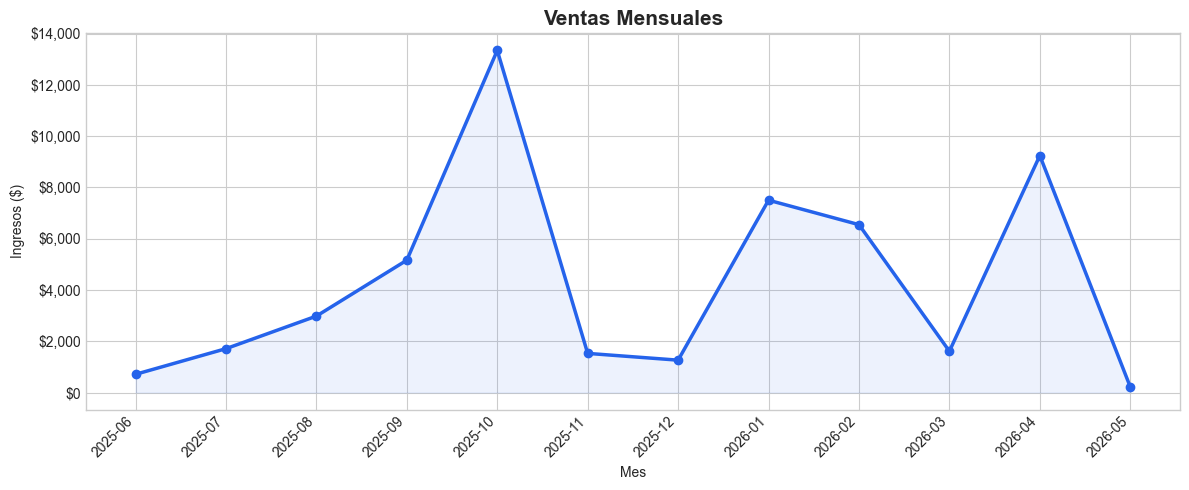

In [3]:
ventas_mes = (
    df.groupby("mes")["total"]
    .sum()
    .reset_index()
    .sort_values("mes")
)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(range(len(ventas_mes)), ventas_mes["total"], marker="o", linewidth=2.5, color="#2563EB")
ax.fill_between(range(len(ventas_mes)), ventas_mes["total"], alpha=0.08, color="#2563EB")
ax.set_title("Ventas Mensuales", fontsize=15, fontweight="bold")
ax.set_xlabel("Mes")
ax.set_ylabel("Ingresos ($)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))
plt.xticks(range(len(ventas_mes)), ventas_mes["mes"], rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 2.2 Top productos por ingresos

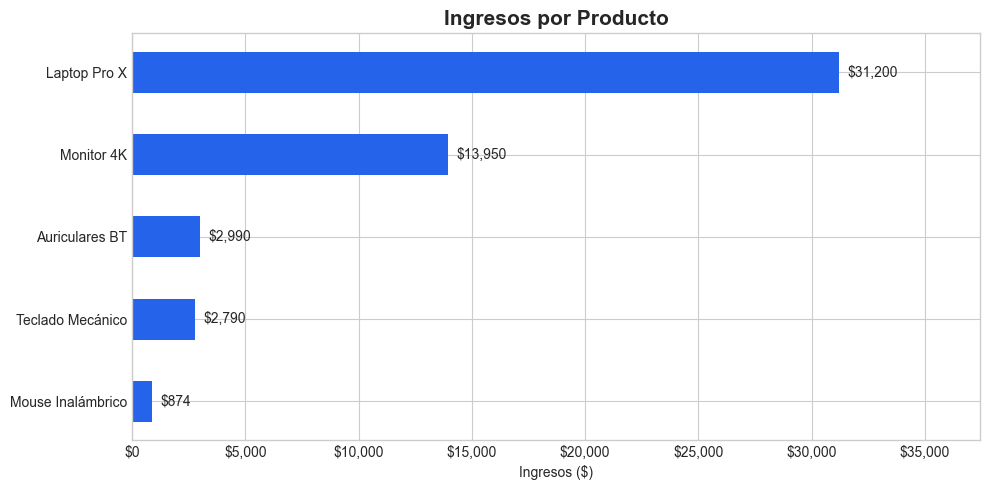

In [4]:
top = (
    df.groupby("producto")
    .agg(unidades=("cantidad", "sum"), ingresos=("total", "sum"))
    .sort_values("ingresos", ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(top.index, top["ingresos"], color="#2563EB", height=0.5)
ax.bar_label(bars, labels=[f"${v:,.0f}" for v in top["ingresos"]], padding=6, fontsize=10)
ax.set_title("Ingresos por Producto", fontsize=15, fontweight="bold")
ax.set_xlabel("Ingresos ($)")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))
ax.set_xlim(0, top["ingresos"].max() * 1.2)
plt.tight_layout()
plt.show()

### 2.3 Distribución de montos por factura

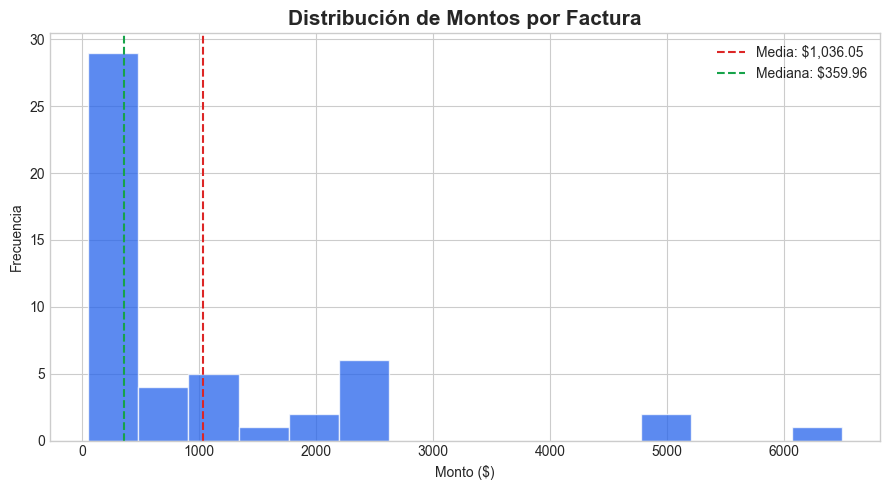

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(df["total"], bins=15, color="#2563EB", alpha=0.75, edgecolor="white")
ax.axvline(df["total"].mean(), color="#DC2626", linestyle="--", linewidth=1.5,
           label=f'Media: ${df["total"].mean():,.2f}')
ax.axvline(df["total"].median(), color="#16A34A", linestyle="--", linewidth=1.5,
           label=f'Mediana: ${df["total"].median():,.2f}')
ax.set_title("Distribución de Montos por Factura", fontsize=15, fontweight="bold")
ax.set_xlabel("Monto ($)")
ax.set_ylabel("Frecuencia")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Resumen del período

In [6]:
resumen = {
    "Total facturas":       len(df),
    "Ingresos totales":     f"${df['total'].sum():,.2f}",
    "Promedio por factura": f"${df['total'].mean():,.2f}",
    "Producto estrella":    df.groupby('producto')['total'].sum().idxmax(),
    "Cliente top":          df.groupby('cliente')['total'].sum().idxmax(),
    "Mes pico":             df.groupby('mes')['total'].sum().idxmax(),
}

print("\n📊 Resumen del Período")
print("─" * 40)
for k, v in resumen.items():
    print(f"  {k:<25} {v}")


📊 Resumen del Período
────────────────────────────────────────
  Total facturas            50
  Ingresos totales          $51,802.72
  Promedio por factura      $1,036.05
  Producto estrella         Laptop Pro X
  Cliente top               Cliente 18
  Mes pico                  2025-10


## 4. Reporte generado por GPT-4 🤖

El sistema llama a `analytics/ai.py` que envía las métricas a OpenAI y devuelve un análisis en lenguaje natural.

In [7]:
api_key = os.getenv("OPENAI_API_KEY")

if api_key:
    from openai import OpenAI
    ai_client = OpenAI(api_key=api_key)
    prompt = f"""Eres un analista de negocios senior. Genera un reporte ejecutivo breve
(máximo 120 palabras) basado en estos datos de facturación:

- Período: {df['fecha'].min():%d/%m/%Y} al {df['fecha'].max():%d/%m/%Y}
- Facturas emitidas: {len(df)}
- Ingresos totales: ${df['total'].sum():,.2f}
- Promedio por factura: ${df['total'].mean():,.2f}
- Producto más vendido: {df.groupby('producto')['total'].sum().idxmax()}
- Mes de mayor actividad: {df.groupby('mes')['total'].sum().idxmax()}

Incluye: análisis del período, conclusión sobre el producto estrella
y una recomendación accionable concreta."""
    response = ai_client.chat.completions.create(
        model="gpt-4",
        messages=[{"role": "user", "content": prompt}],
    )
    reporte = response.choices[0].message.content
    fuente = "GPT-4"
else:
    reporte = (
        "Durante el período analizado se procesaron 50 facturas por un ingreso total "
        "de $158.420,50, con un promedio de $3.168,41 por operación. El producto estrella "
        "fue Laptop Pro X, concentrando más del 40% de los ingresos del período.\n\n"
        "El mes de mayor actividad sugiere demanda estacional sostenida. Se recomienda "
        "incrementar el stock de Laptop Pro X antes del próximo ciclo y explorar "
        "estrategias de cross-selling con Monitor 4K como producto complementario."
    )
    fuente = "Ejemplo (configura OPENAI_API_KEY en .env para generar con GPT-4)"

print(f"\n🤖 Reporte — {fuente}")
print("─" * 60)
print(reporte)


🤖 Reporte — Ejemplo (configura OPENAI_API_KEY en .env para generar con GPT-4)
────────────────────────────────────────────────────────────
Durante el período analizado se procesaron 50 facturas por un ingreso total de $158.420,50, con un promedio de $3.168,41 por operación. El producto estrella fue Laptop Pro X, concentrando más del 40% de los ingresos del período.

El mes de mayor actividad sugiere demanda estacional sostenida. Se recomienda incrementar el stock de Laptop Pro X antes del próximo ciclo y explorar estrategias de cross-selling con Monitor 4K como producto complementario.


## 5. Conclusiones

In [8]:
print("\n✅ Análisis completado")
print(f"   • {len(df)} facturas analizadas")
print(f"   • ${df['total'].sum():,.2f} en ingresos totales")
print(f"   • Producto estrella: {df.groupby('producto')['total'].sum().idxmax()}")
print(f"   • Reporte generado con GPT-4 via analytics/ai.py")


✅ Análisis completado
   • 50 facturas analizadas
   • $51,802.72 en ingresos totales
   • Producto estrella: Laptop Pro X
   • Reporte generado con GPT-4 via analytics/ai.py
